# Peak width and height across a GC-MS screening design

**Question:** Which of the seven parameters significantly change peak width or height, and are they the same for early- and late-eluting standards?

**Data:** Gamble, S.; Granger, C.; Mannion, J. *GC-MS Screening Data for Instrument Optimization*. figshare, 2025. https://doi.org/10.6084/m9.figshare.28635920.v1 (license GPL 3.0+). Accessed 2026-11-08.

## Imports

Purpose: load the libraries used below. Expected output: none.

In [1]:
import sys

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.signal import peak_widths

## Parameters

Purpose: numbers that encode a choice about these data. `N_METHODS` comes from the design: a two-level fractional factorial in seven factors with 32 runs. Expected output: none.

In [2]:
N_METHODS = 32  # runs in the design (ffd.csv), one chromatogram each
TIC_HEADER_LINES = 2  # text lines before the data in each TIC file: run name, "Start of data points"

Peak-measurement parameters, chosen from the data before any effects are computed: the peak full widths at half height (FWHM) run from 0.022 to 0.067 min and data points are 0.0036 min apart; the closest pair of standards (iodohexane and iodobenzene in Method 24) is 0.625 min apart; the earliest standard (iodopropane in Method 12) elutes at 4.12 min, and recording starts at 4.00 min.

In [3]:
PEAK_WINDOW_MIN = 0.15  # min, half-width of the window around each listed retention time: > 2 x the widest FWHM (0.067 min), < half the closest gap between standards (0.625 min)
CHECK_WINDOW_MIN = 0.25  # min, a wider window used only to test whether a result depends on the window
BASELINE_EDGE_POINTS = 5  # points averaged at each end of the window to anchor the straight baseline (5 x 0.0036 = 0.018 min)
APEX_TOLERANCE_MIN = 0.01  # min, largest allowed distance from apex to listed retention time: about half the narrowest FWHM
MIN_POINTS_ACROSS = 5  # data points across the FWHM below which the width is not trusted
WINDOW_SENSITIVITY = 0.10  # fraction, largest allowed change in height or width between the two windows

## Load the data

Purpose: read the design, the retention times and all 32 chromatograms from `data/`, exactly as downloaded.

Scientific choice: each TIC file starts with a byte-order mark and two text lines, so it is read with `skiprows=TIC_HEADER_LINES` and `encoding="utf-8-sig"`. The 32 chromatograms are stacked into one long table with a `method` column, so later steps can work on one method at a time with `groupby`. Nothing in the files is edited.

One row of `design` is one method and its seven factor levels (A to G). One row of `retention_times` is one method's retention time for each of the 11 standards, in min. One row of `tic` is one time point of one chromatogram: time in min and total ion current in counts.

Expected output: 32 rows in `design` and in `retention_times`, and about 425,000 rows in `tic`.

In [4]:
def read_tic(method):
    """Read one chromatogram as downloaded.

    Parameters
    ----------
    method : int
        Method number, 1 to N_METHODS.

    Returns
    -------
    pandas.DataFrame
        Columns `method`, `time` (min) and `intensity` (counts).
    """
    chromatogram = pd.read_csv(
        f"data/TIC_Method_{method}.csv",
        skiprows=TIC_HEADER_LINES,
        header=None,
        names=["time", "intensity"],  # min, counts
        encoding="utf-8-sig",
    )
    chromatogram.insert(0, "method", method)
    return chromatogram


design = pd.read_csv("data/ffd.csv")  # factor levels per method, columns A-G
retention_times = pd.read_csv("data/rts.csv", index_col="Chemical")  # min
tic = pd.concat(
    [read_tic(method) for method in range(1, N_METHODS + 1)], ignore_index=True
)  # time in min, intensity in counts

print(f"design: {len(design)} rows, columns {list(design.columns)}")
print(f"retention_times: {len(retention_times)} rows, {len(retention_times.columns)} standards")
print(f"tic: {len(tic)} rows, columns {list(tic.columns)}")

design: 32 rows, columns ['Method', 'A', 'B', 'C', 'D', 'E', 'F', 'G']
retention_times: 32 rows, 11 standards
tic: 425125 rows, columns ['method', 'time', 'intensity']


## Check for problems on loading

Purpose: look for missing or non-numeric values, check the column types, and check that the three tables name the same 32 methods.

Scientific choice: a value that could not be read as a number would show up as an `object` column or a missing value. The method names in `rts.csv` ("Method 1") differ in format from the numbers in `ffd.csv` (1), so they are compared after taking the number off the name.

Expected output: zero missing values, numeric columns everywhere, and empty sets for the methods missing from either table. Per method, the number of points and the time range in min.

In [5]:
print("missing values:")
print(f"  design {design.isna().sum().sum()}, "
      f"retention_times {retention_times.isna().sum().sum()}, "
      f"tic {tic.isna().sum().sum()}")
print("column types in tic:", dict(tic.dtypes.astype(str)))

rts_methods = set(retention_times.index.str.split(" ").str[1].astype(int))
design_methods = set(design["Method"])
tic_methods = set(tic["method"])
print("in design but not in rts:", design_methods - rts_methods)
print("in design but not in tic:", design_methods - tic_methods)

per_method = tic.groupby("method").agg(
    points=("time", "size"),
    start=("time", "min"),  # min
    end=("time", "max"),  # min
    max_intensity=("intensity", "max"),  # counts
    min_intensity=("intensity", "min"),  # counts
)
print()
print(per_method.to_string())

missing values:
  design 0, retention_times 0, tic 0
column types in tic: {'method': 'int64', 'time': 'float64', 'intensity': 'float64'}
in design but not in rts: set()
in design but not in tic: set()

        points    start       end  max_intensity  min_intensity
method                                                         
1        16245  4.00090  63.00315   1.010000e+09       35608.15
2        10325  4.00150  41.50165   4.290466e+07       34513.53
3        10326  4.00088  41.50185   4.210000e+08       29572.80
4        16246  4.00088  63.00403   5.690000e+08       35154.72
5        10326  4.00088  41.50322   1.130000e+09       36803.97
6        16244  4.00088  63.00222   2.350000e+07       26807.25
7        16245  4.00088  63.00175   2.930000e+08       31755.22
8        10326  4.00090  41.50163   7.870000e+08       37031.79
9        16244  4.00088  63.00063   2.100000e+07       29754.72
10       10325  4.00088  41.50137   9.810000e+08       37018.94
11       10326  4.00088  41.50

## Raw chromatograms with the listed retention times

Purpose: before measuring any peak, check that the retention times in `rts.csv` sit on real peaks in the TIC, and look at the baseline and at anything that is not one of the 11 standards.

Scientific choice: the two methods are picked from the data, not by hand: the slowest method (latest iodododecane retention time) and the fastest (earliest), so together they bracket the design. Each gets its own panel because their peak heights differ about 30-fold. The y-axis is capped at 1.2 times the tallest standard so the standards stay readable; the cell prints the largest value the cap hides and where it is.

Expected output: two panels of intensity (counts) against time (min), a dashed line numbered 1 to 11 at each standard's listed retention time, and one printed line per method about what is above the axis.

Method 22: largest value 9.76e+08 counts at 5.61 min is above the axis; clipped points span 5.04-6.95 min
Method 3: nothing clipped
numbers 1-11: iodopropane, iodobutane, iodopentane, iodohexane, iodobenzene, iodoheptane, iodooctane, iodononane, iododecane, iodoundecane, iodododecane


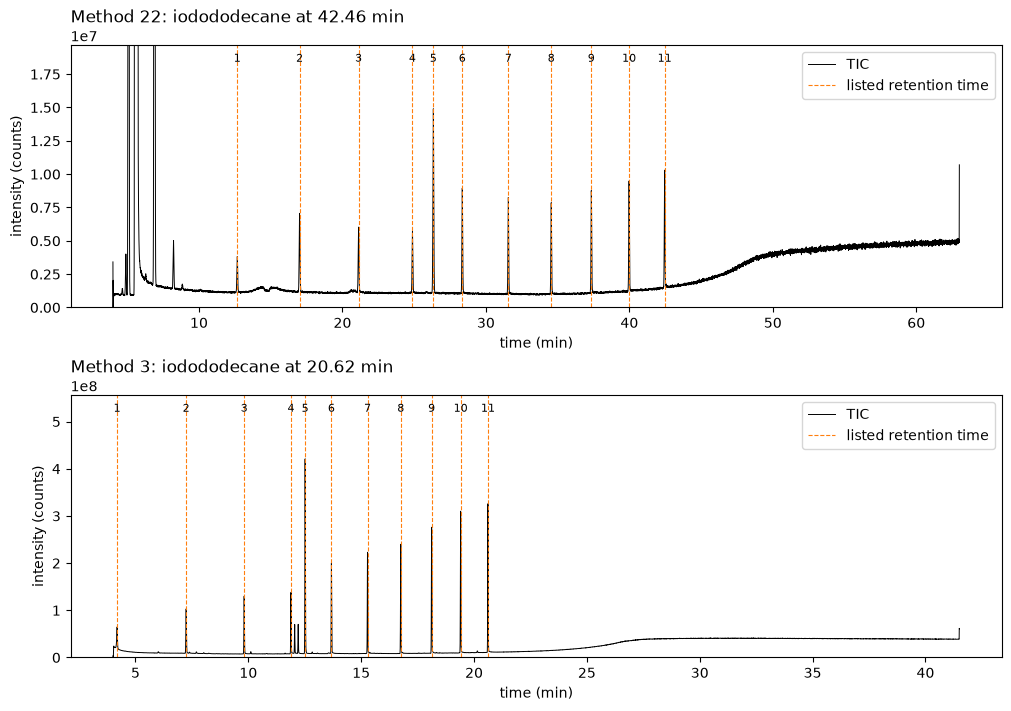

In [6]:
last_standard = retention_times.columns[-1]  # iodododecane, elutes last
example_labels = [
    retention_times[last_standard].idxmax(),  # slowest method
    retention_times[last_standard].idxmin(),  # fastest method
]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), layout="constrained")
for ax, label in zip(axes, example_labels):
    method = int(label.split(" ")[1])
    chromatogram = tic[tic["method"] == method]
    time = chromatogram["time"].to_numpy()  # min
    intensity = chromatogram["intensity"].to_numpy()  # counts
    method_rts = retention_times.loc[label].to_numpy()  # min

    # tallest standard: TIC value at each listed retention time, counts
    standard_heights = np.interp(method_rts, time, intensity)
    y_cap = 1.2 * standard_heights.max()  # counts, display only

    ax.plot(time, intensity, color="black", linewidth=0.7, label="TIC")
    for number, rt in enumerate(method_rts, start=1):
        ax.axvline(rt, color="tab:orange", linestyle="--", linewidth=0.8,
                   label="listed retention time" if number == 1 else None)
        ax.text(rt, 1.02 * y_cap, str(number), ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, 1.1 * y_cap)
    ax.set_xlabel("time (min)")
    ax.set_ylabel("intensity (counts)")
    ax.set_title(f"{label}: {last_standard} at {retention_times.loc[label, last_standard]:.2f} min",
                 loc="left")
    ax.legend(loc="upper right")

    clipped = intensity > 1.1 * y_cap
    if clipped.any():
        print(f"{label}: largest value {intensity.max():.3g} counts at "
              f"{time[intensity.argmax()]:.2f} min is above the axis; "
              f"clipped points span {time[clipped].min():.2f}-{time[clipped].max():.2f} min")
    else:
        print(f"{label}: nothing clipped")

print("numbers 1-11:", ", ".join(retention_times.columns))
plt.show()

In both the slowest and the fastest method each of the 11 dashed lines falls on a peak, so `rts.csv` can locate the peaks; the off-scale peaks between 5.0 and 7.0 min in Method 22 are not standards, and in Method 3 iodopropane (1) elutes only 0.19 min after recording starts at 4.0 min, on the falling edge of the start of the trace.

## Measure height and width of every peak

Purpose: measure the height (counts) and the full width at half maximum (FWHM, min) of each of the 11 standards in each of the 32 methods, 352 peaks, and flag those that cannot be trusted.

Scientific choices:
- The window is the listed retention time ± `PEAK_WINDOW_MIN`. Step 1 showed the listed times sit on the peaks.
- The baseline is a straight line between the mean of the first and the last `BASELINE_EDGE_POINTS` points of the window, so a sloping baseline (such as the falling start of the trace under early iodopropane) is removed rather than counted as peak.
- Height is the largest baseline-corrected value in the window. FWHM comes from `scipy.signal.peak_widths` at half that height, which interpolates linearly between points, so widths are not limited to multiples of the 0.0036 min point spacing.
- A peak is flagged if its apex is more than `APEX_TOLERANCE_MIN` from the listed time, if fewer than `MIN_POINTS_ACROSS` points span its FWHM, if its window runs past the start of the recording, or if remeasuring it with `CHECK_WINDOW_MIN` changes its height or width by more than `WINDOW_SENSITIVITY`. Flagged peaks are kept in the table, so that excluding them is a separate, visible decision.

Expected output: a table `peaks` with 352 rows; a summary of heights (about 10⁶ to 10⁸ counts) and widths (about 0.02 to 0.07 min); the number of peaks raising each flag; and the list of flagged peaks.

In [7]:
def measure_peak(time, intensity, retention_time, half_window):
    """Measure one peak's height and FWHM above a straight local baseline.

    Parameters
    ----------
    time : numpy.ndarray
        Time of each point of one chromatogram, min.
    intensity : numpy.ndarray
        TIC at each point, counts.
    retention_time : float
        Listed retention time of the standard, min.
    half_window : float
        Half-width of the window around `retention_time`, min.

    Returns
    -------
    dict
        `height` (counts), `fwhm` (min), `apex_time` (min),
        `points_across` (points spanning the FWHM) and `truncated`
        (True if the window starts before the recording does).
    """
    in_window = (time >= retention_time - half_window) & (time <= retention_time + half_window)
    window_time = time[in_window]  # min
    window_intensity = intensity[in_window]  # counts

    edge_times = [window_time[:BASELINE_EDGE_POINTS].mean(), window_time[-BASELINE_EDGE_POINTS:].mean()]  # min
    edge_levels = [window_intensity[:BASELINE_EDGE_POINTS].mean(),
                   window_intensity[-BASELINE_EDGE_POINTS:].mean()]  # counts
    corrected = window_intensity - np.interp(window_time, edge_times, edge_levels)  # counts

    apex = int(corrected.argmax())
    points_across, _, left, right = (values[0] for values in peak_widths(corrected, [apex], rel_height=0.5))
    point_index = np.arange(len(window_time))
    fwhm = np.interp(right, point_index, window_time) - np.interp(left, point_index, window_time)  # min

    return {
        "height": corrected[apex],  # counts
        "fwhm": fwhm,  # min
        "apex_time": window_time[apex],  # min
        "points_across": points_across,
        "truncated": retention_time - half_window < time[0],
    }


rows = []
for method, chromatogram in tic.groupby("method"):
    time = chromatogram["time"].to_numpy()  # min
    intensity = chromatogram["intensity"].to_numpy()  # counts
    for standard, retention_time in retention_times.loc[f"Method {method}"].items():
        main = measure_peak(time, intensity, retention_time, PEAK_WINDOW_MIN)
        check = measure_peak(time, intensity, retention_time, CHECK_WINDOW_MIN)
        rows.append({
            "method": method,
            "standard": standard,
            "elution_order": retention_times.columns.get_loc(standard) + 1,
            "retention_time": retention_time,  # min
            **main,
            "height_change": check["height"] / main["height"] - 1,  # fraction
            "fwhm_change": check["fwhm"] / main["fwhm"] - 1,  # fraction
        })
peaks = pd.DataFrame(rows)

peaks["flag_apex"] = (peaks["apex_time"] - peaks["retention_time"]).abs() > APEX_TOLERANCE_MIN
peaks["flag_points"] = peaks["points_across"] < MIN_POINTS_ACROSS
peaks["flag_truncated"] = peaks["truncated"]
peaks["flag_window"] = (peaks[["height_change", "fwhm_change"]].abs() > WINDOW_SENSITIVITY).any(axis=1)
flag_columns = ["flag_apex", "flag_points", "flag_truncated", "flag_window"]
peaks["flagged"] = peaks[flag_columns].any(axis=1)

print(f"{len(peaks)} peaks measured")
print(peaks[["height", "fwhm", "points_across"]].describe().loc[["min", "50%", "max"]].to_string())
print()
print("peaks raising each flag:", peaks[flag_columns].sum().to_dict())
print(f"flagged in total: {peaks['flagged'].sum()} of {len(peaks)}")
print()
print(peaks.loc[peaks["flagged"], ["method", "standard", "height", "fwhm", "apex_time", "retention_time",
                                   "height_change", "fwhm_change", *flag_columns]].to_string(index=False))

352 peaks measured
           height      fwhm  points_across
min  2.693615e+06  0.022128       6.095979
50%  3.569280e+07  0.037631      10.358812
max  4.124468e+08  0.066963      18.433549

peaks raising each flag: {'flag_apex': 2, 'flag_points': 0, 'flag_truncated': 4, 'flag_window': 6}
flagged in total: 12 of 352

 method     standard       height     fwhm  apex_time  retention_time  height_change  fwhm_change  flag_apex  flag_points  flag_truncated  flag_window
      3  iodopropane 4.515019e+07 0.034352    4.18612           4.186       0.283153     0.259062      False        False           False         True
      7  iodopropane 4.474010e+07 0.034737    4.18975           4.190       0.217856     0.193507      False        False           False         True
      9 iodoundecane 9.140529e+06 0.046129   32.42415          32.435       0.001978     0.001859       True        False           False        False
     11   iodohexane 9.964000e+07 0.029559   15.64922          15.649       

## Environment

Purpose: record the Python and package versions this notebook ran with. Expected output: Python 3.14 and the versions from `uv.lock`.

In [8]:
print(f"Python {sys.version.split()[0]}")
print(f"numpy {np.__version__}")
print(f"pandas {pd.__version__}")
print(f"scipy {scipy.__version__}")
print(f"matplotlib {matplotlib.__version__}")

Python 3.14.7
numpy 2.5.3
pandas 3.0.6
scipy 1.18.1
matplotlib 3.11.2
